# Análisis de Cantera

## Librerías

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from math import pi
import warnings
warnings.filterwarnings('ignore')

## Carga de datos del filial

In [28]:
# Definición de rutas
ruta_data = Path.cwd().parent.parent / 'data' / 'laspalmasb'

# Carga del dataset individual del filial
try:
    df_lpa = pd.read_excel(ruta_data / 'Las Palmas Atletico 25_26.xlsx')
    # Rellenar NaNs en métricas por 90 con 0 para evitar errores de cálculo
    df_lpa = df_lpa.fillna(0)
    print(f"Cargados {len(df_lpa)} jugadores de Las Palmas Atlético.")
except FileNotFoundError:
    print("Archivo no encontrado. Verifica que 'Las Palmas Atletico 25_26.xlsx' está en la carpeta data.")

Cargados 26 jugadores de Las Palmas Atlético.


## Motor de evaluación

In [11]:
# Perfiles definidos en la Fase de Captaciones
PERFILES_OBJETIVO = {
    'Portero': {
        'metricas': [
            'Short / medium passes per 90', 'Forward passes per 90', 
            'Long passes per 90', 'Conceded goals per 90', 'Prevented goals per 90'
        ],
        'pesos': [0.15, 0.15, 0.15, 0.25, 0.30]
    },
    'Defensa central': {
        'metricas': [
            'Defensive duels per 90', 'Interceptions per 90', 'Aerial duels per 90',
            'Passes to final third per 90', 'Progressive runs per 90'
        ],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10]
    },
    'Lateral': {
        # Laterales profundos pero con capacidad de retorno y pase interior
        'metricas': [
            'Progressive runs per 90', 'Crosses per 90', 'Passes to final third per 90',
            'Defensive duels per 90', 'Interceptions per 90'
        ],
        'pesos': [0.25, 0.20, 0.25, 0.15, 0.15]
    },
    'Mediocentro': {
        # Pivotes y mediocentros (DMF/CMF) con gran volumen de distribución y corrección
        'metricas': [
            'Passes to final third per 90', 'Forward passes per 90',
            'Defensive duels per 90', 'Interceptions per 90', 'Progressive runs per 90'
        ],
        'pesos': [0.30, 0.20, 0.25, 0.15, 0.10]
    },
    'Mediocentro ofensivo': {
        'metricas': [
            'Passes to final third per 90', 'Key passes per 90', 
            'Progressive runs per 90', 'Dribbles per 90', 'xA per 90'
        ],
        'pesos': [0.30, 0.25, 0.20, 0.15, 0.10]
    },
    'Extremo': {
        # Engloba RW y LW: perfiles de desborde y generación de ocasiones
        'metricas': [
            'Dribbles per 90', 'Progressive runs per 90', 'Crosses per 90', 
            'xA per 90', 'Touches in box per 90'
        ],
        'pesos': [0.30, 0.25, 0.15, 0.15, 0.15]
    },
    'Delantero centro': {
        # Puntas con movilidad, presencia en área y finalización
        'metricas': [
            'Goals per 90', 'xG per 90', 'Touches in box per 90', 
            'Shots per 90', 'Offensive duels per 90'
        ],
        'pesos': [0.35, 0.25, 0.20, 0.10, 0.10]
    }
}

def normalizar_y_puntuar(df_filial, posicion_buscada, perfil):
    """
    Filtra por posición, normaliza las métricas respecto a los compañeros 
    del filial y calcula el Score de "Preparación para el Salto".
    Filtramos también por minutos jugados (>300) para evitar muestras poco representativas.
    """
    metricas = perfil['metricas']
    pesos = perfil['pesos']
    
    # Filtrar por posición y minutos mínimos
    df_pos = df_filial[(df_filial['Position'].str.contains(posicion_buscada, na=False)) & 
                       (df_filial['Minutes played'] > 300)].copy()
    
    if df_pos.empty:
        return pd.DataFrame()
        
    df_norm = df_pos.copy()
    
    # Normalización Min-Max sobre el propio contexto del filial
    for metrica in metricas:
        minimo = df_pos[metrica].min()
        maximo = df_pos[metrica].max()
        rango = maximo - minimo
        
        if rango == 0:
            df_norm[metrica] = 0.5
        else:
            df_norm[metrica] = (df_pos[metrica] - minimo) / rango
            
    # Calcular Score Ponderado sobre 10
    df_pos['Score_Promocion'] = sum(df_norm[m] * p for m, p in zip(metricas, pesos)) * 10
    df_pos['Score_Promocion'] = df_pos['Score_Promocion'].round(2)
    
    # Ordenar Ranking
    ranking = df_pos[['Player', 'Age', 'Minutes played', 'Score_Promocion'] + metricas].sort_values('Score_Promocion', ascending=False)
    
    return ranking

## Detección de talento

In [15]:
def evaluar_talento_cantera(df_filial, posicion_buscada, clave_perfil, perfiles_objetivo):
    """
    Filtra a los jugadores por posición, normaliza sus métricas respecto al grupo
    y calcula el Score de Promoción basado en el perfil objetivo.
    """
    if clave_perfil not in perfiles_objetivo:
        print(f"Error: El perfil '{clave_perfil}' no está definido en el diccionario.")
        return pd.DataFrame()
        
    perfil = perfiles_objetivo[clave_perfil]
    metricas = perfil['metricas']
    pesos = perfil['pesos']
    
    # Filtrar por posición y un mínimo de minutos jugados (>300) para dar validez estadística
    df_pos = df_filial[(df_filial['Position'].str.contains(posicion_buscada, na=False)) & 
                       (df_filial['Minutes played'] > 300)].copy()
    
    if df_pos.empty:
        print(f"  -> No se encontraron jugadores con >300 min para: {posicion_buscada}")
        return pd.DataFrame()
        
    df_norm = df_pos.copy()
    
    # Normalización Min-Max dinámica sobre el propio contexto del filial
    for metrica in metricas:
        if metrica not in df_pos.columns:
            print(f"  -> Aviso: La métrica '{metrica}' no existe en el DataFrame. Se evaluará como 0.")
            df_norm[metrica] = 0
            continue
            
        minimo = df_pos[metrica].min()
        maximo = df_pos[metrica].max()
        rango = maximo - minimo
        
        # Evitar división por cero si todos los jugadores tienen exactamente el mismo valor
        if rango == 0:
            df_norm[metrica] = 0.5
        else:
            df_norm[metrica] = (df_pos[metrica] - minimo) / rango
            
    # Calcular Score Ponderado sobre 10
    df_pos['Score_Promocion'] = sum(df_norm[m] * p for m, p in zip(metricas, pesos)) * 10
    df_pos['Score_Promocion'] = df_pos['Score_Promocion'].round(2)
    
    # Retornar el DataFrame ordenado de mejor a peor
    cols_salida = ['Player', 'Position', 'Age', 'Minutes played', 'Score_Promocion'] + metricas
    return df_pos[cols_salida].sort_values('Score_Promocion', ascending=False)

## Visualización radar

In [16]:
def visualizar_radar_cantera(df_ranking, clave_perfil, perfiles_objetivo):
    """
    Genera un Radar Chart del mejor prospecto (Top 1) del ranking 
    contra la huella táctica ideal del primer equipo.
    """
    if df_ranking.empty:
        return
        
    perfil = perfiles_objetivo[clave_perfil]
    metricas = perfil['metricas']
    pesos = perfil['pesos']
    
    # Extraer automáticamente al prospecto con mayor puntuación
    mejor_jugador = df_ranking.iloc[0]
    nombre = mejor_jugador['Player']
    
    # Normalizar los valores del jugador respecto al máximo del filial para darle forma al radar
    maximos = df_ranking[metricas].max().replace(0, 1) # replace(0,1) evita división por cero
    valores_jugador = (mejor_jugador[metricas] / maximos).fillna(0).tolist()
    valores_jugador += valores_jugador[:1] # Cerrar el polígono del radar
    
    # Generar la forma del perfil ideal (normalizado según sus pesos algorítmicos)
    max_peso = max(pesos)
    valores_ideal = [p / max_peso for p in pesos]
    valores_ideal += valores_ideal[:1]
    
    # Configuración geométrica del Radar
    n = len(metricas)
    angulos = [i / float(n) * 2 * pi for i in range(n)]
    angulos += angulos[:1]
    nombres_cortos = [m.replace(' per 90', '') for m in metricas]
    
    # Dibujar la figura
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True), facecolor='#F8FAFC')
    ax.set_facecolor('#F8FAFC')
    
    plt.xticks(angulos[:-1], nombres_cortos, color='#003057', size=11, fontweight='bold')
    ax.set_rlabel_position(0)
    plt.yticks([], []) # Ocultar las anillas interiores numéricas para mayor estética
    
    # Trazar Perfil Ideal (Primer Equipo)
    ax.plot(angulos, valores_ideal, linewidth=2, color='#1E293B', linestyle='--', label=f'Ideal 1er Equipo ({clave_perfil})')
    ax.fill(angulos, valores_ideal, color='#1E293B', alpha=0.1)
    
    # Trazar Prospecto Cantera (Top 1 del algoritmo)
    ax.plot(angulos, valores_jugador, linewidth=2.5, color='#005BBB', label=f'Prospecto: {nombre}')
    ax.fill(angulos, valores_jugador, color='#FFD700', alpha=0.4)
    
    # Formato de títulos y leyenda
    plt.title(f'Test de Promoción: {clave_perfil}', size=16, color='#003057', y=1.1, fontweight='bold')
    plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=11)
    
    plt.tight_layout()
    plt.show()

## Ejecución

In [24]:
def visualizar_resumen_promocion(df_top_prospectos):
    """
    Genera un Lollipop Chart ejecutivo mostrando al mejor prospecto de cada posición,
    ordenado por su nivel de preparación.
    """
    if df_top_prospectos.empty:
        return
        
    # Ordenar de menor a mayor para que el gráfico horizontal muestre al mejor arriba
    df_plot = df_top_prospectos.sort_values('Score_Promocion', ascending=True).reset_index(drop=True)
    
    # Crear etiquetas combinando Nombre, Posición y Edad
    etiquetas = df_plot['Player'] + " (" + df_plot['Posicion_Buscada'] + " | " + df_plot['Age'].astype(str) + " años)"
    scores = df_plot['Score_Promocion']
    
    # Configuración de la figura
    fig, ax = plt.subplots(figsize=(10, max(5, len(df_plot) * 0.8)), facecolor='#F8FAFC')
    ax.set_facecolor('#F8FAFC')
    
    # Dibujar las líneas (el 'palo' de la piruleta)
    ax.hlines(y=etiquetas, xmin=0, xmax=scores, color='#1E293B', alpha=0.4, linewidth=2)
    
    # Dibujar los puntos (el 'caramelo' de la piruleta)
    # Usamos los colores corporativos: Azul para la base, Amarillo para el punto
    ax.plot(scores, etiquetas, "o", markersize=14, color='#FFD700', markeredgecolor='#005BBB', markeredgewidth=2)
    
    # Añadir el número exacto del Score dentro/cerca de la burbuja
    for i, v in enumerate(scores):
        ax.text(v + 0.2, i, f"{v:.1f}/10", color='#003057', va='center', fontweight='bold', fontsize=10)

    # Diseño y limpieza de los ejes
    ax.set_xlim(0, 11) # Dar margen visual hasta el 10
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    # Cuadrícula sutil solo en el eje X
    ax.xaxis.grid(True, linestyle='--', alpha=0.3, color='gray')
    ax.set_axisbelow(True)
    
    # Textos
    plt.title('Mapa de promoción por posición', fontsize=16, fontweight='bold', color='#003057', pad=20)
    plt.xlabel('Score', fontsize=12, color='#003057')
    plt.yticks(fontsize=11, fontweight='bold', color='#1E293B')
    
    plt.tight_layout()
    plt.show()

Auditoría filial...

Evaluando PORTERO...


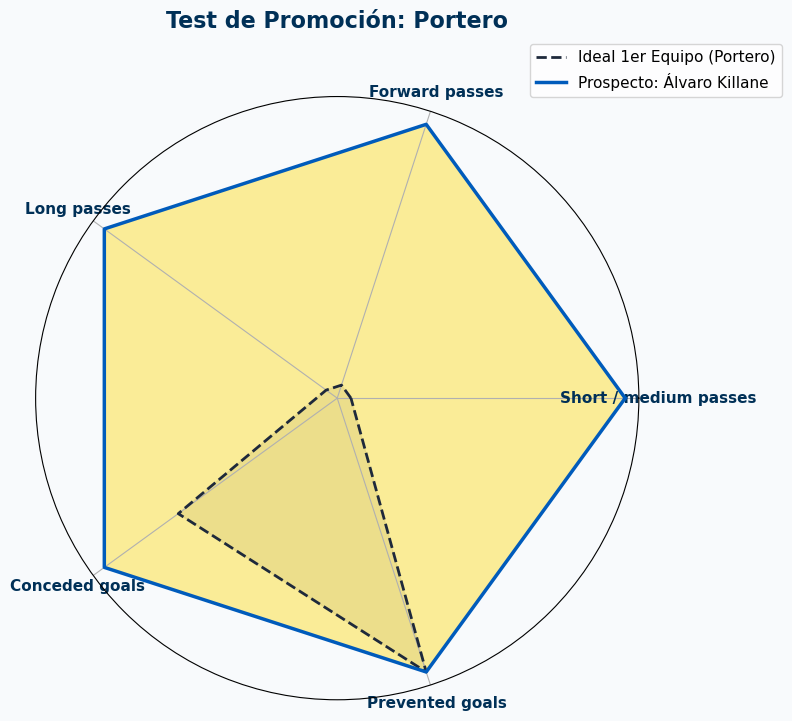

Evaluando DEFENSA CENTRAL...


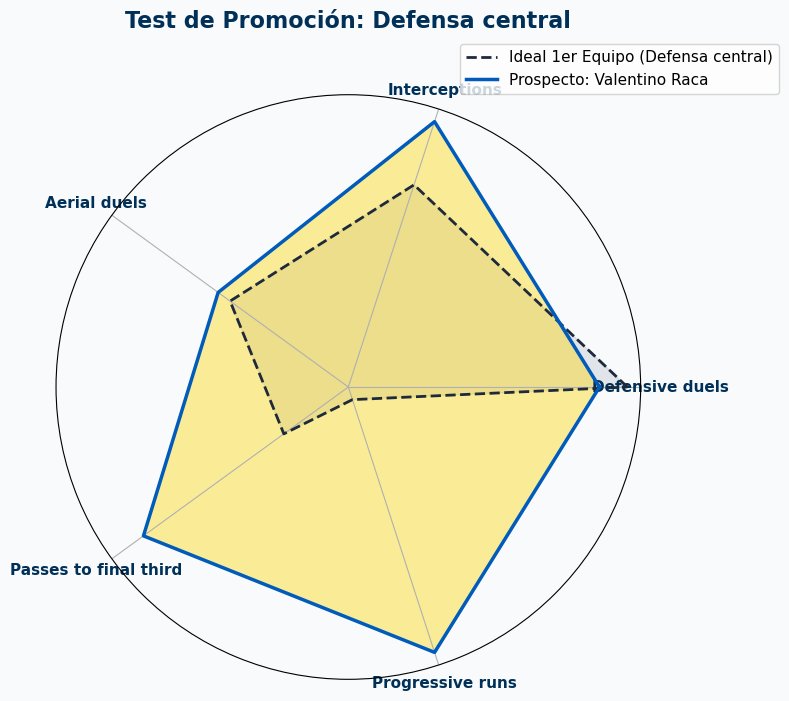

Evaluando LATERAL...


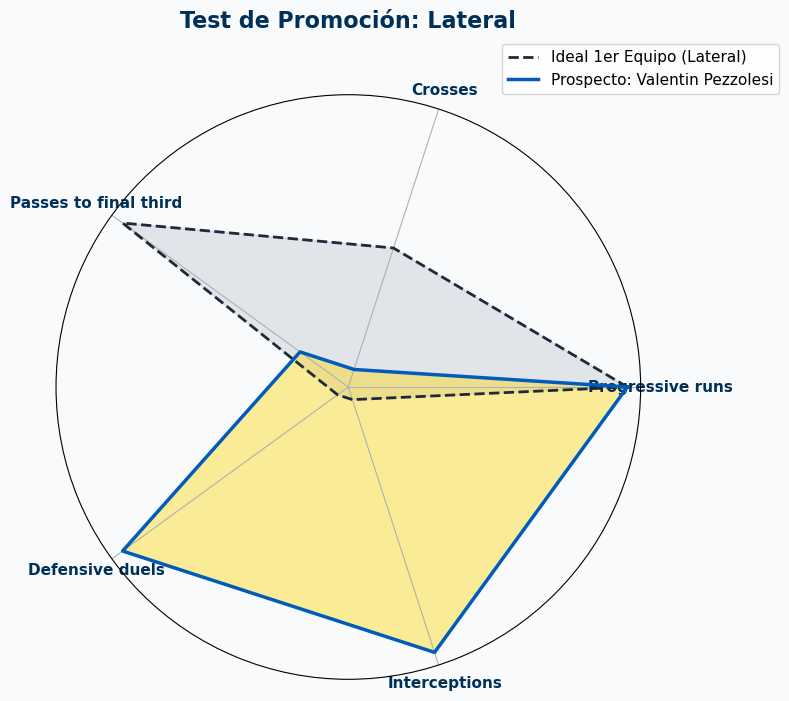

Evaluando MEDIOCENTRO...


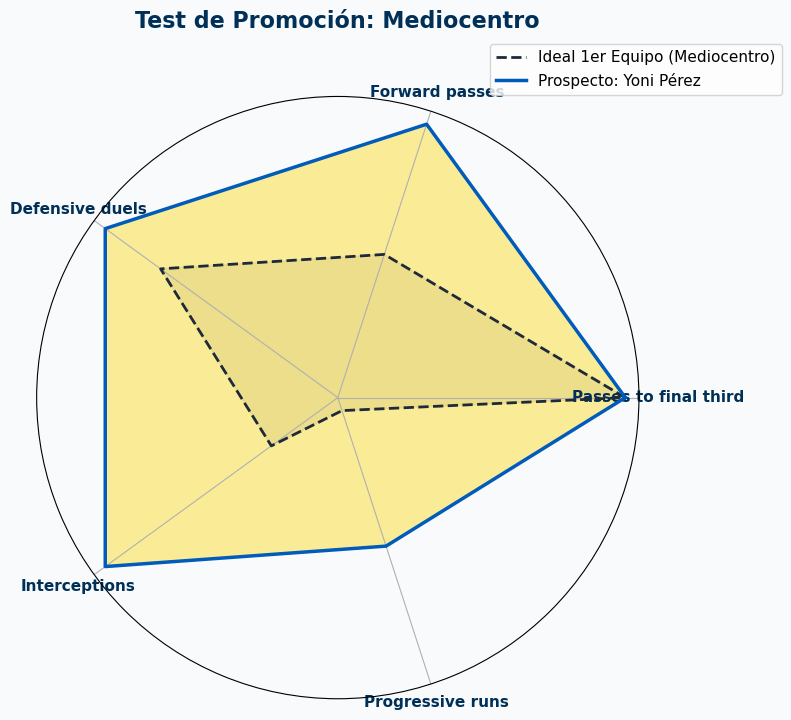

Evaluando MEDIOCENTRO OFENSIVO...


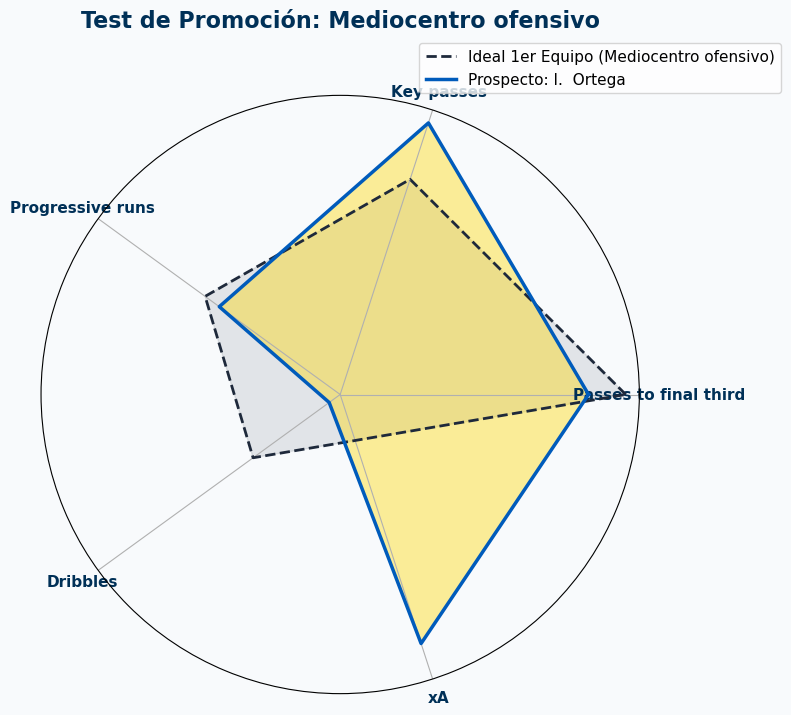

Evaluando EXTREMO...


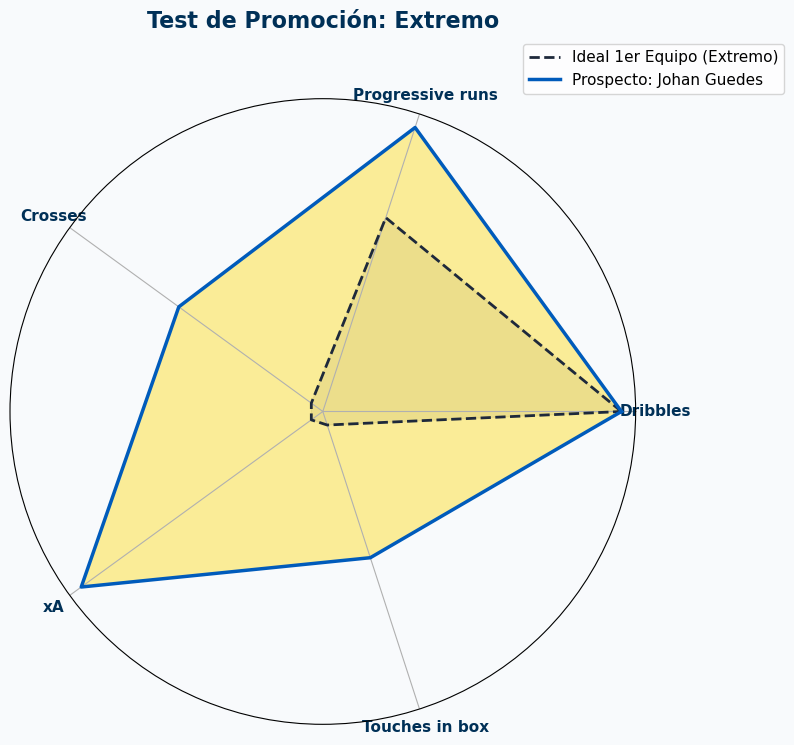

Evaluando DELANTERO CENTRO...


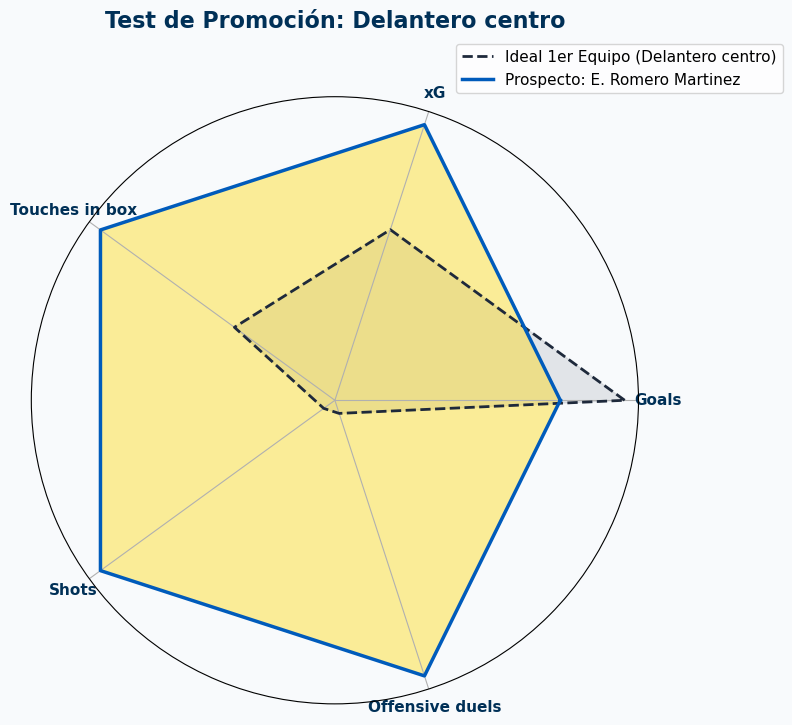

In [25]:
# Definimos las posiciones que la Secretaría Técnica quiere auditar en el filial
posiciones_a_evaluar = [
    ('GK', 'Portero'),
    ('CB', 'Defensa central'),
    ('RB|LB', 'Lateral'),
    ('CMF|DMF', 'Mediocentro'),
    ('AMF', 'Mediocentro ofensivo'),
    ('RW|LW', 'Extremo'),
    ('CF', 'Delantero centro')
]

print("Auditoría filial...\n")

# Lista para recolectar al mejor jugador de cada demarcación
mejores_por_posicion = []

for siglas_posicion, nombre_perfil in posiciones_a_evaluar:
    print(f"Evaluando {nombre_perfil.upper()}...")
    
    # Llamar a la función de Detección (Scoring)
    ranking = evaluar_talento_cantera(df_lpa, siglas_posicion, nombre_perfil, PERFILES_OBJETIVO)
    
    if not ranking.empty:
        # Extraer al Top 1 para el resumen final
        top_1 = ranking.iloc[0].copy()
        top_1['Posicion_Buscada'] = nombre_perfil
        mejores_por_posicion.append(top_1)
        
        # Visualizar el Radar de este jugador
        visualizar_radar_cantera(ranking, nombre_perfil, PERFILES_OBJETIVO)
    else:
        print(f"Sin talento con +300 min en {nombre_perfil}.")


Jugador filial por posición...



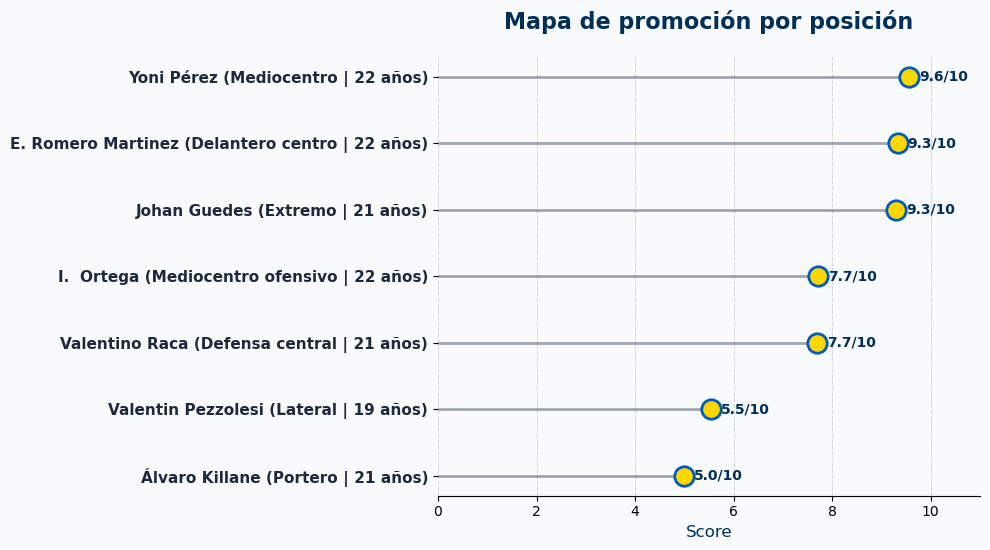

,Player,Posicion_Buscada,Age,Minutes played,Score_Promocion
0,Yoni Pérez,Mediocentro,22,723,9.56
1,E. Romero Martinez,Delantero centro,22,1782,9.33
2,Johan Guedes,Extremo,21,1329,9.30
3,I. Ortega,Mediocentro ofensivo,22,1965,7.71
4,Valentino Raca,Defensa central,21,1375,7.70
5,Valentin Pezzolesi,Lateral,19,628,5.55
6,Álvaro Killane,Portero,21,1976,5.00


In [26]:
# Resumen
print("\n" + "="*60)
print("Jugador filial por posición...")
print("="*60 + "\n")

if mejores_por_posicion:
    # Convertir la lista recolectada en un DataFrame
    df_resumen_global = pd.DataFrame(mejores_por_posicion)
    
    # Llamar a nuestra nueva visualización
    visualizar_resumen_promocion(df_resumen_global)
    
    # Opcional: Mostrar una tablita limpia por pantalla
    display_cols = ['Player', 'Posicion_Buscada', 'Age', 'Minutes played', 'Score_Promocion']
    display(df_resumen_global[display_cols].sort_values('Score_Promocion', ascending=False).reset_index(drop=True))

## Exportación

In [29]:
def evaluar_cantera_masivo(df_filial, posicion_buscada, clave_perfil, perfiles_objetivo):
    """
    Evalúa a todos los jugadores de una posición y devuelve un DataFrame 
    con los scores de todos los aptos (>300 min), etiquetando el perfil evaluado.
    """
    perfil = perfiles_objetivo[clave_perfil]
    metricas = perfil['metricas']
    pesos = perfil['pesos']
    
    df_pos = df_filial[(df_filial['Position'].str.contains(posicion_buscada, na=False)) & 
                       (df_filial['Minutes played'] > 300)].copy()
    
    if df_pos.empty:
        return pd.DataFrame()
        
    df_norm = df_pos.copy()
    
    for metrica in metricas:
        if metrica not in df_pos.columns:
            df_norm[metrica] = 0
            continue
            
        minimo = df_pos[metrica].min()
        maximo = df_pos[metrica].max()
        rango = maximo - minimo
        
        if rango == 0:
            df_norm[metrica] = 0.5
        else:
            df_norm[metrica] = (df_pos[metrica] - minimo) / rango
            
    df_pos['Score_Promocion'] = sum(df_norm[m] * p for m, p in zip(metricas, pesos)) * 10
    df_pos['Score_Promocion'] = df_pos['Score_Promocion'].round(2)
    df_pos['Perfil_Evaluado'] = clave_perfil
    
    cols_salida = ['Player', 'Perfil_Evaluado', 'Position', 'Age', 'Minutes played', 'Score_Promocion'] + metricas
    return df_pos[cols_salida].sort_values('Score_Promocion', ascending=False)

In [32]:
posiciones_a_evaluar = [
    ('GK', 'Portero'), ('CB', 'Defensa central'), ('RB|LB', 'Lateral'),
    ('CMF|DMF', 'Mediocentro'), ('AMF', 'Mediocentro ofensivo'),
    ('RW|LW', 'Extremo'), ('CF', 'Delantero centro')
]

lista_resultados = []

for siglas, perfil in posiciones_a_evaluar:
    df_resultado = evaluar_cantera_masivo(df_lpa, siglas, perfil, PERFILES_OBJETIVO)
    if not df_resultado.empty:
        lista_resultados.append(df_resultado)

# Unificar todo en un solo DataFrame maestro
df_cantera_scores = pd.concat(lista_resultados, ignore_index=True)

In [35]:
# Exportación del Dataset de Scores
ruta_exportacion = ruta_data / 'scores_cantera_2627.csv'
df_cantera_scores.to_csv(ruta_exportacion, index=False, encoding='utf-8-sig')

print("="*60)
print(f"Exportación")
print(f"   Archivo generado: {ruta_exportacion.name}")
print(f"   Total de jugadores del filial evaluados y guardados: {len(df_cantera_scores)}")
print("="*60)

# Vista previa de los 5 jugadores con mayor puntuación absoluta en el filial
display(df_cantera_scores[['Player', 'Perfil_Evaluado', 'Age', 'Score_Promocion']].sort_values('Score_Promocion', ascending=False))

Exportación
   Archivo generado: scores_cantera_2627.csv
   Total de jugadores del filial evaluados y guardados: 31


,Player,Perfil_Evaluado,Age,Score_Promocion
8,Yoni Pérez,Mediocentro,22,9.56
27,E. Romero Martinez,Delantero centro,22,9.33
21,Johan Guedes,Extremo,21,9.30
22,E. Romero Martinez,Extremo,22,8.80
13,I. Ortega,Mediocentro ofensivo,22,7.71
1,Valentino Raca,Defensa central,21,7.70
14,Johan Guedes,Mediocentro ofensivo,21,7.28
23,A. Guzmán Castillo,Extremo,23,6.58
15,E. Romero Martinez,Mediocentro ofensivo,22,6.00
16,A. Guzmán Castillo,Mediocentro ofensivo,23,5.76
